In [5]:
# Activity 1: Dataset Preparation

# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Step 2: Upload the Titanic dataset
from google.colab import files

uploaded = files.upload()

# Step 3: Load the CSV file
df = pd.read_csv('train.csv')

# Step 4: Display a success message
print("Dataset loaded successfully!")


Saving train.csv to train.csv
Dataset loaded successfully!


In [6]:
# Display first five rows
print("First five rows:")
display(df.head())

# Display last five rows
print("\nLast five rows:")
display(df.tail())

First five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Last five rows:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


In [7]:
# Check the number of rows and columns
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 891
Number of columns: 12
Dataset shape: (891, 12)


In [8]:
# Display all column names
print("Column Names:")
print(df.columns.tolist())


Column Names:
['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked']


In [9]:
# Display information about the dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [10]:
# Identify numerical columns
numerical_columns = df.select_dtypes(include=np.number).columns.tolist()

# Identify categorical columns
categorical_columns = df.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numerical Columns:")
print(numerical_columns)

print("\nCategorical Columns:")
print(categorical_columns)


Numerical Columns:
['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

Categorical Columns:
['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [11]:
# Statistical summary of numerical columns
print("Summary Statistics:")
display(df.describe())


Summary Statistics:


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [12]:
# Summary of categorical columns
print("Categorical Data Summary:")
display(df.describe(include=['object']))

Categorical Data Summary:


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Dooley, Mr. Patrick",male,347082,G6,S
freq,1,577,7,4,644


In [13]:
# Identify the possible target variable
target_column = 'Survived'

print("Target Column:", target_column)
print("Unique Target Values:", df[target_column].unique())
print("\nTarget Frequency:")
print(df[target_column].value_counts())


Target Column: Survived
Unique Target Values: [0 1]

Target Frequency:
Survived
0    549
1    342
Name: count, dtype: int64


In [14]:
# Count missing values in each column

missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
display(missing_values)


Missing Values in Each Column:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


In [15]:
# Calculate percentage of missing values

missing_percentage = (df.isnull().sum() / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

print("Missing Value Summary:")
display(missing_summary)


Missing Value Summary:


,Missing Values,Missing Percentage
PassengerId,0,0.000000
Survived,0,0.000000
Pclass,0,0.000000
Name,0,0.000000
Sex,0,0.000000
Age,177,19.865320
SibSp,0,0.000000
Parch,0,0.000000
Ticket,0,0.000000
Fare,0,0.000000


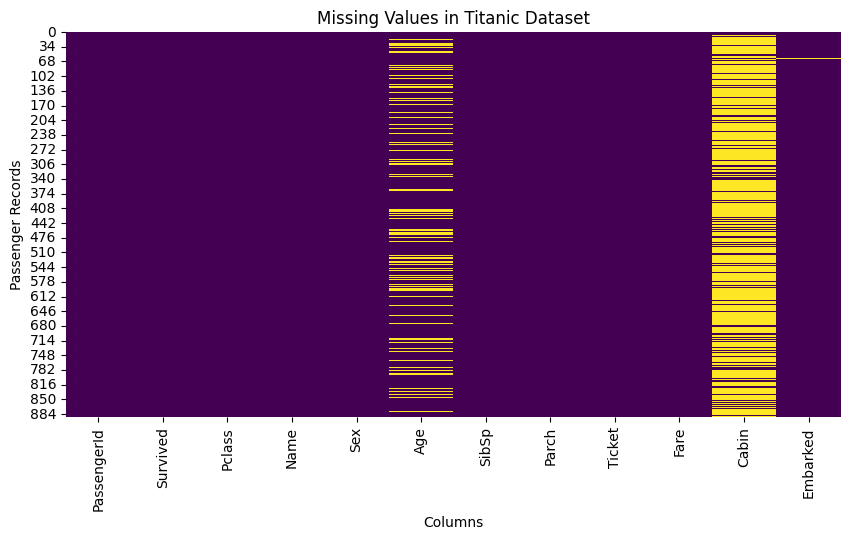

In [16]:
# Visualisation of missing values

plt.figure(figsize=(10, 5))

sns.heatmap(df.isnull(), cbar=False, cmap='viridis')

plt.title("Missing Values in Titanic Dataset")
plt.xlabel("Columns")
plt.ylabel("Passenger Records")

plt.show()

In [17]:
# Create a copy of the original dataset

df_clean = df.copy()

print("Original dataset shape:", df.shape)
print("Copied dataset shape:", df_clean.shape)
print("Backup created successfully!")


Original dataset shape: (891, 12)
Copied dataset shape: (891, 12)
Backup created successfully!


In [18]:
# Handle missing values

# Replace missing Age values with median
df_clean['Age'] = df_clean['Age'].fillna(df_clean['Age'].median())

# Replace missing Cabin values with Unknown
df_clean['Cabin'] = df_clean['Cabin'].fillna('Unknown')

# Replace missing Embarked values with mode
df_clean['Embarked'] = df_clean['Embarked'].fillna(df_clean['Embarked'].mode()[0])

print("Missing values handled successfully!")


Missing values handled successfully!


In [19]:
print("Missing values after cleaning:")
display(df_clean.isnull().sum())

print("\nTotal remaining missing values:",
      df_clean.isnull().sum().sum())

Missing values after cleaning:


,0
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,0
SibSp,0
Parch,0
Ticket,0
Fare,0



Total remaining missing values: 0


In [20]:
# Check duplicate records

duplicate_count = df_clean.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)


Number of duplicate rows: 0


In [21]:
# Check unique values in categorical columns

for column in categorical_columns:
    print("\nUnique values in", column)
    print(df_clean[column].unique())



Unique values in Name
['Braund, Mr. Owen Harris'
 'Cumings, Mrs. John Bradley (Florence Briggs Thayer)'
 'Heikkinen, Miss. Laina' 'Futrelle, Mrs. Jacques Heath (Lily May Peel)'
 'Allen, Mr. William Henry' 'Moran, Mr. James' 'McCarthy, Mr. Timothy J'
 'Palsson, Master. Gosta Leonard'
 'Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)'
 'Nasser, Mrs. Nicholas (Adele Achem)' 'Sandstrom, Miss. Marguerite Rut'
 'Bonnell, Miss. Elizabeth' 'Saundercock, Mr. William Henry'
 'Andersson, Mr. Anders Johan' 'Vestrom, Miss. Hulda Amanda Adolfina'
 'Hewlett, Mrs. (Mary D Kingcome) ' 'Rice, Master. Eugene'
 'Williams, Mr. Charles Eugene'
 'Vander Planke, Mrs. Julius (Emelia Maria Vandemoortele)'
 'Masselmani, Mrs. Fatima' 'Fynney, Mr. Joseph J' 'Beesley, Mr. Lawrence'
 'McGowan, Miss. Anna "Annie"' 'Sloper, Mr. William Thompson'
 'Palsson, Miss. Torborg Danira'
 'Asplund, Mrs. Carl Oscar (Selma Augusta Emilia Johansson)'
 'Emir, Mr. Farred Chehab' 'Fortune, Mr. Charles Alexander'
 'O\'Dwyer, Miss. 

In [22]:
# Remove leading and trailing spaces

for column in categorical_columns:
    df_clean[column] = df_clean[column].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

print("Categorical text cleaning completed!")


Categorical text cleaning completed!


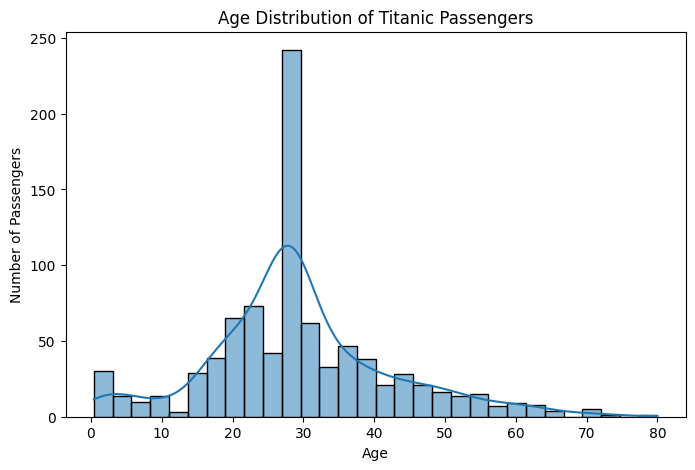

In [23]:
plt.figure(figsize=(8, 5))
sns.histplot(df_clean['Age'], bins=30, kde=True)

plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()


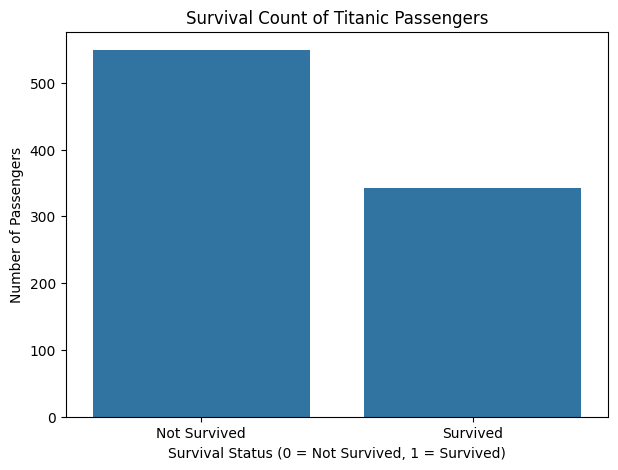

In [24]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='Survived')

plt.title("Survival Count of Titanic Passengers")
plt.xlabel("Survival Status (0 = Not Survived, 1 = Survived)")
plt.ylabel("Number of Passengers")

plt.xticks([0, 1], ['Not Survived', 'Survived'])
plt.show()

In [25]:
print("EDA Observations:")
print("1. Most passengers belonged to the young adult age group.")
print("2. The number of passengers who did not survive was higher than the number who survived.")
print("3. The age distribution shows that passengers belonged to different age groups.")

EDA Observations:
1. Most passengers belonged to the young adult age group.
2. The number of passengers who did not survive was higher than the number who survived.
3. The age distribution shows that passengers belonged to different age groups.


In [26]:
df_prepared = df_clean.drop(
    columns=['PassengerId', 'Name', 'Ticket', 'Cabin']
)

print("Unnecessary columns removed successfully!")
print("Remaining columns:")
print(df_prepared.columns.tolist())
print("\nCurrent dataset shape:", df_prepared.shape)

Unnecessary columns removed successfully!
Remaining columns:
['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Current dataset shape: (891, 8)


In [27]:
df_prepared = pd.get_dummies(
    df_prepared,
    columns=['Sex', 'Embarked'],
    dtype=int
)

print("One-Hot Encoding completed successfully!")
print("\nUpdated column names:")
print(df_prepared.columns.tolist())

print("\nFirst five encoded records:")
display(df_prepared.head())

One-Hot Encoding completed successfully!

Updated column names:
['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

First five encoded records:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,0,1,0,0,1
1,1,1,38.0,1,0,71.2833,1,0,1,0,0
2,1,3,26.0,0,0,7.9250,1,0,0,0,1
3,1,1,35.0,1,0,53.1000,1,0,0,0,1
4,0,3,35.0,0,0,8.0500,0,1,0,0,1


In [28]:
from sklearn.preprocessing import StandardScaler

# Select numerical input features (exclude target column)
numerical_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

scaler = StandardScaler()

df_prepared[numerical_features] = scaler.fit_transform(
    df_prepared[numerical_features]
)

print("Feature scaling completed successfully!")
print("\nScaled numerical features:")
display(df_prepared[numerical_features].head())

print("\nFinal dataset shape:", df_prepared.shape)

Feature scaling completed successfully!

Scaled numerical features:


,Pclass,Age,SibSp,Parch,Fare
0,0.827377,-0.565736,0.432793,-0.473674,-0.502445
1,-1.566107,0.663861,0.432793,-0.473674,0.786845
2,0.827377,-0.258337,-0.474545,-0.473674,-0.488854
3,-1.566107,0.433312,0.432793,-0.473674,0.420730
4,0.827377,0.433312,-0.474545,-0.473674,-0.486337



Final dataset shape: (891, 11)


In [29]:
print("Final Dataset Information:")
print("\nDataset Shape:", df_prepared.shape)

print("\nColumn Names:")
print(df_prepared.columns.tolist())

print("\nFirst Five Records:")
display(df_prepared.head())

print("\nMissing Values:")
print(df_prepared.isnull().sum())

print("\nData Types:")
print(df_prepared.dtypes)

Final Dataset Information:

Dataset Shape: (891, 11)

Column Names:
['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S']

First Five Records:


,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_female,Sex_male,Embarked_C,Embarked_Q,Embarked_S
0,0,0.827377,-0.565736,0.432793,-0.473674,-0.502445,0,1,0,0,1
1,1,-1.566107,0.663861,0.432793,-0.473674,0.786845,1,0,1,0,0
2,1,0.827377,-0.258337,-0.474545,-0.473674,-0.488854,1,0,0,0,1
3,1,-1.566107,0.433312,0.432793,-0.473674,0.420730,1,0,0,0,1
4,0,0.827377,0.433312,-0.474545,-0.473674,-0.486337,0,1,0,0,1



Missing Values:
Survived      0
Pclass        0
Age           0
SibSp         0
Parch         0
Fare          0
Sex_female    0
Sex_male      0
Embarked_C    0
Embarked_Q    0
Embarked_S    0
dtype: int64

Data Types:
Survived        int64
Pclass        float64
Age           float64
SibSp         float64
Parch         float64
Fare          float64
Sex_female      int64
Sex_male        int64
Embarked_C      int64
Embarked_Q      int64
Embarked_S      int64
dtype: object


In [30]:
df_prepared.to_csv('titanic_prepared.csv', index=False)

print("Prepared dataset saved successfully!")
print("File Name: titanic_prepared.csv")

Prepared dataset saved successfully!
File Name: titanic_prepared.csv


In [31]:
from google.colab import files

files.download('titanic_prepared.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Conclusion

In this activity, the Titanic dataset was used to understand and perform data preprocessing techniques required for machine learning.

The following tasks were completed:

1. Loaded and explored the dataset using Python and Pandas.
2. Identified numerical and categorical features.
3. Analysed missing values and handled them using median, mode and an 'Unknown' category.
4. Checked and removed duplicate records, if any.
5. Performed Exploratory Data Analysis (EDA) using histograms and count plots.
6. Applied One-Hot Encoding to categorical features.
7. Applied StandardScaler for numerical feature scaling.
8. Exported the final cleaned and prepared dataset into CSV format.

**Result:** The Titanic dataset was successfully cleaned, analysed, transformed and saved as `titanic_prepared.csv`. The prepared dataset is ready for further machine learning activities.



